In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

In [22]:
# --- 1. 解决中文乱码 (如上所述) ---
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False

In [27]:
# --- 2. 准备数据与向量提取 ---
print(f"开始处理 {len(df)} 条文本...")
instruction = "判断相关文本是否属于固定资产类型，以便进行准确的文本分类："
texts_with_instruction = [instruction + str(t) for t in df['text'].tolist()]

# 核心优化：batch_size 建议设为 16 或 32（取决于显存/内存）
# show_progress_bar=True 会在控制台显示 tqdm 进度条
X = model.encode(
    texts_with_instruction, 
    batch_size=16, 
    show_progress_bar=True, 
    convert_to_numpy=True
)
y = df['label'].values

开始处理 100 条文本...


Batches: 100%|██████████| 7/7 [00:22<00:00,  3.27s/it]


In [ ]:
# --- 3. 定义多种分类算法 ---
# 注意：KNN(n=1) 等价于“直接根据相似度分类”，即 Qwen3 的判断
models = {
    "逻辑回归 (LR)": LogisticRegression(class_weight='balanced'),
    "支持向量机 (SVM)": SVC(kernel='linear', probability=True),
    "随机森林 (RF)": RandomForestClassifier(n_estimators=100),
    "相似度匹配 (KNN-1)": KNeighborsClassifier(n_neighbors=1),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1),
}

In [34]:
# --- 4. 交叉验证对比准确度 ---
results = []
for name, clf in models.items():
    # cv=5 表示 5 折交叉验证，100条数据分5份，轮流验证
    scores = cross_val_score(clf, X, y, cv=5)
    results.append({"算法": name, "准确度": scores.mean()})

C:\Users\13398\AppData\Local\Temp\ipykernel_21824\2212059125.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="准确度", y="算法", data=res_df, palette="Blues_d")


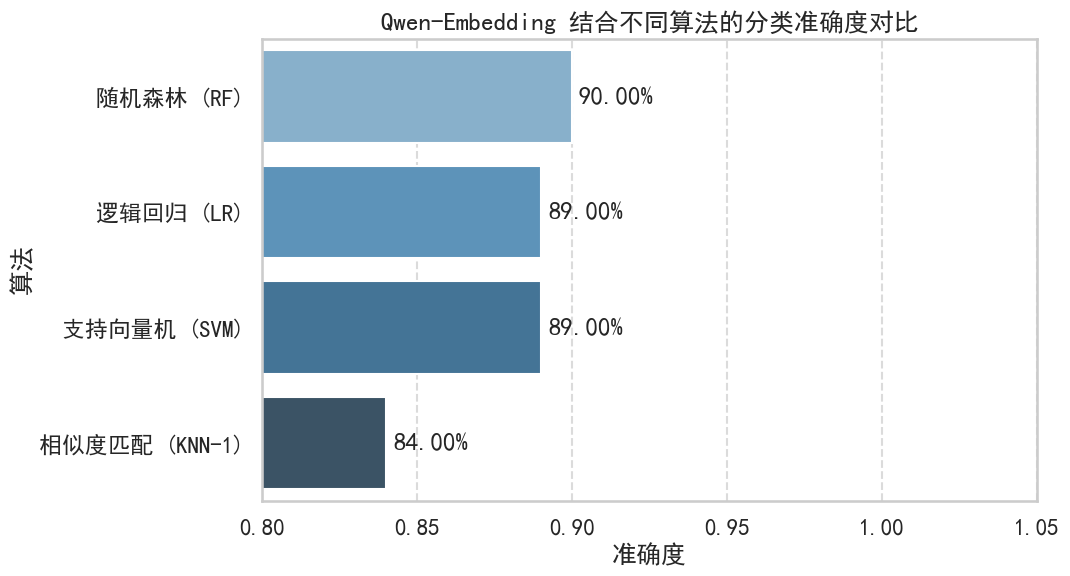

In [35]:
# --- 5. 绘图展示 ---
res_df = pd.DataFrame(results).sort_values("准确度", ascending=False)
plt.figure(figsize=(10, 6))
sns.set_context("talk")
ax = sns.barplot(x="准确度", y="算法", data=res_df, palette="Blues_d")

# 在柱状图上标注具体数值
for p in ax.patches:
    ax.annotate(f'{p.get_width():.2%}', (p.get_width(), p.get_y() + p.get_height()/2),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points')

plt.title("Qwen-Embedding 结合不同算法的分类准确度对比")
plt.xlim(0.8, 1.05) # 聚焦高准确度区间
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()